<a href="https://colab.research.google.com/github/aswathiunnikrishnan/Assignment--1/blob/main/Assignment05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Preprocessing

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler

1. Data Exploration

In [44]:
df = pd.read_csv('/content/Employee.csv')
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


In [45]:
print("Shape:",df.shape)
print("Columns:",df.columns.tolist())
df.info()
df.describe()
df.describe(include='all')


Shape: (148, 6)
Columns: ['Company', 'Age', 'Salary', 'Place', 'Country', 'Gender']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    object 
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    object 
 4   Country  148 non-null    object 
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 7.1+ KB


,Company,Age,Salary,Place,Country,Gender
count,140,130.000000,124.000000,134,148,148.000000
unique,6,NaN,NaN,11,1,NaN
top,TCS,NaN,NaN,Mumbai,India,NaN
freq,53,NaN,NaN,37,148,NaN
mean,NaN,30.484615,5312.467742,NaN,NaN,0.222973
std,NaN,11.096640,2573.764683,NaN,NaN,0.417654
min,NaN,0.000000,1089.000000,NaN,NaN,0.000000
25%,NaN,22.000000,3030.000000,NaN,NaN,0.000000
50%,NaN,32.500000,5000.000000,NaN,NaN,0.000000
75%,NaN,37.750000,8000.000000,NaN,NaN,0.000000


In [46]:
for columns in df.columns:
  print("\nColumn:",columns)
  unique_values = df[columns].unique()
  print("Unique values:",unique_values)
  print("Length:",len(unique_values))


Column: Company
Unique values: ['TCS' 'Infosys' 'CTS' nan 'Tata Consultancy Services' 'Congnizant'
 'Infosys Pvt Lmt']
Length: 7

Column: Age
Unique values: [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.]
Length: 30

Column: Salary
Unique values: [  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 9000. 1089. 1234. 3030.
 3045. 3184. 4824. 5835. 7084. 8943. 8345. 9284. 9876. 2034. 7654. 2934.
 4034. 5034. 8202. 9024. 4345. 6544. 6543. 3234. 4324. 5435. 5555. 8787.
 3454. 5654. 5009. 5098. 3033.]
Length: 41

Column: Place
Unique values: ['Chennai' 'Mumbai' 'Calcutta' 'Delhi' 'Podicherry' 'Cochin' nan 'Noida'
 'Hyderabad' 'Bhopal' 'Nagpur' 'Pune']
Length: 12

Column: Country
Unique values: ['India']
Length: 1

Column: Gender
Unique values: [0 1]
Length: 2


Renaming Columns

In [47]:
df.rename(columns ={'Company':'Company_Name','Age':'Employee_Age','Salary':'Employee_salary','Place':'Location','Country':'Country_name','Gender':'Gender'},inplace=True)
df.head()

,Company_Name,Employee_Age,Employee_salary,Location,Country_name,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


2. Data Cleaning

In [48]:
#missing values
print(df.isnull().sum())
print(df.isnull().sum()/len(df)*100)

Company_Name        8
Employee_Age       18
Employee_salary    24
Location           14
Country_name        0
Gender              0
dtype: int64
Company_Name        5.405405
Employee_Age       12.162162
Employee_salary    16.216216
Location            9.459459
Country_name        0.000000
Gender              0.000000
dtype: float64


In [49]:
#inappropriate values
df[df['Employee_Age']==0]
df['Employee_Age']= df['Employee_Age'].replace(0,np.nan)


In [50]:
#removing duplicate rows
print("Duplicate:",df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicates After removal:",df.duplicated().sum())

Duplicate: 4
Duplicates After removal: 0


In [51]:
#find outliers
numeric_columns = ['Employee_Age','Employee_salary']

for column in numeric_columns:
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3-Q1
  lower_limit = Q1-1.5*IQR
  upper_limit = Q3+1.5*IQR

  outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

  print("\nolumn:",column)
  print("Lower limit:",lower_limit)
  print("Upper limit:",upper_limit)
  print("Number of outliers:",len(outliers))


olumn: Employee_Age
Lower limit: -2.5
Upper limit: 65.5
Number of outliers: 0

olumn: Employee_salary
Lower limit: -4425.0
Upper limit: 15455.0
Number of outliers: 0


In [52]:
#treat missing values
#numerical columns median
df['Employee_Age'] = df['Employee_Age'].fillna(df['Employee_Age'].median())
df['Employee_salary'] = df['Employee_salary'].fillna(df['Employee_salary'].median())

#categorical columns mode

df['Company_Name'] = df['Company_Name'].fillna(df['Company_Name'].mode()[0])
df['Location'] = df['Location'].fillna(df['Location'].mode()[0])

print(df.isnull().sum())

Company_Name       0
Employee_Age       0
Employee_salary    0
Location           0
Country_name       0
Gender             0
dtype: int64


3. Data Analysis

In [53]:
#age greater than 40 and salary less than 5000

filtered_df = df[(df['Employee_Age']>40) & (df['Employee_salary']<5000)]
print(filtered_df)

    Company_Name  Employee_Age  Employee_salary   Location Country_name  Gender
21       Infosys          50.0           3184.0      Delhi        India       0
32       Infosys          45.0           4034.0   Calcutta        India       0
39       Infosys          41.0           3000.0     Mumbai        India       0
50       Infosys          41.0           3000.0    Chennai        India       0
57       Infosys          51.0           3184.0  Hyderabad        India       0
68       Infosys          43.0           4034.0     Mumbai        India       0
75       Infosys          44.0           3000.0     Cochin        India       0
86       Infosys          41.0           3000.0      Delhi        India       0
93       Infosys          54.0           3184.0     Mumbai        India       0
104      Infosys          44.0           4034.0      Delhi        India       0
122      Infosys          44.0           3234.0     Mumbai        India       0
129      Infosys          50.0          

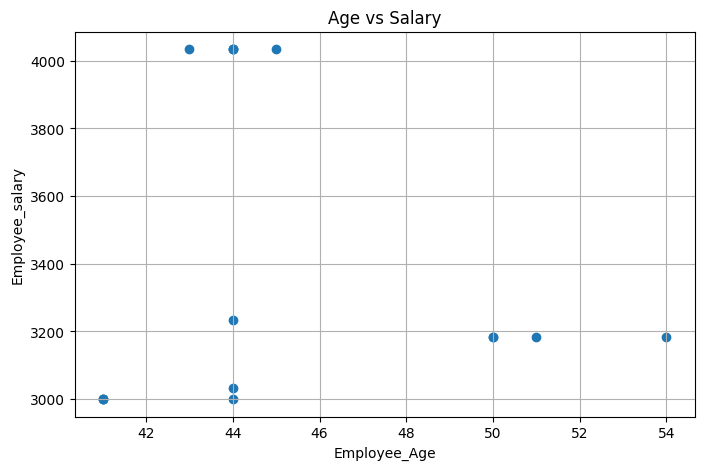

In [54]:
plt.figure(figsize=(8,5))
plt.scatter(filtered_df['Employee_Age'],filtered_df['Employee_salary'])

plt.xlabel('Employee_Age')
plt.ylabel('Employee_salary')
plt.title('Age vs Salary')

plt.grid()
plt.show()


In [55]:
#count of employees freom each place

place_count = df['Location'].value_counts()
print(place_count)

Location
Mumbai        48
Calcutta      32
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


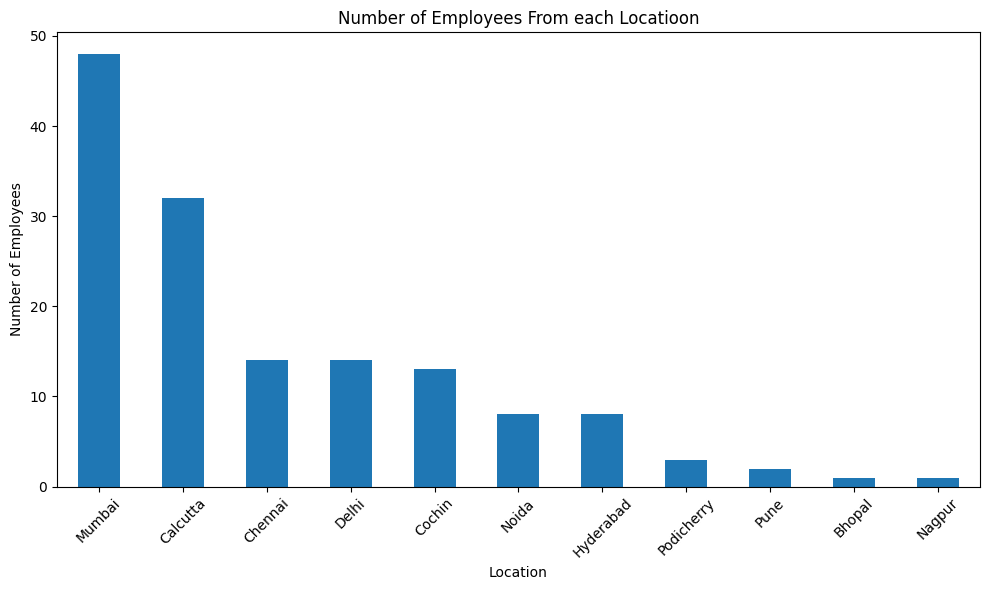

In [56]:
#Employee count by location

plt.figure(figsize=(10,6))
place_count.plot(kind='bar')
plt.xlabel('Location')
plt.ylabel('Number of Employees')
plt.title('Number of Employees From each Locatioon')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4. Data Encoding

In [57]:
categorical_columns = df.select_dtypes(include='object').columns
print(categorical_columns)

Index(['Company_Name', 'Location', 'Country_name'], dtype='object')


In [58]:
df_encoded = pd.get_dummies(df,columns=['Company_Name','Location'],drop_first=True,dtype=int)
print(df_encoded.head())

#we excluded Country_Name because it contains only one unique value

   Employee_Age  Employee_salary  ... Location_Podicherry  Location_Pune
0          20.0           5000.0  ...                   0              0
1          30.0           5000.0  ...                   0              0
2          35.0           2300.0  ...                   0              0
3          40.0           3000.0  ...                   0              0
4          23.0           4000.0  ...                   0              0

[5 rows x 19 columns]


In [59]:
# Label encoding

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_label = df.copy()

for column in ['Company_Name','Location']:
  df_label[column] = le.fit_transform(df_label[column])

  print(df_label.head())

   Company_Name  Employee_Age  Employee_salary  Location Country_name  Gender
0             4          20.0           5000.0   Chennai        India       0
1             2          30.0           5000.0    Mumbai        India       0
2             4          35.0           2300.0  Calcutta        India       0
3             2          40.0           3000.0     Delhi        India       0
4             4          23.0           4000.0    Mumbai        India       0
   Company_Name  Employee_Age  Employee_salary  Location Country_name  Gender
0             4          20.0           5000.0         2        India       0
1             2          30.0           5000.0         6        India       0
2             4          35.0           2300.0         1        India       0
3             2          40.0           3000.0         4        India       0
4             4          23.0           4000.0         6        India       0


5. Feature Scaling


In [60]:
#remove the constant country name column

df_encoded.drop(columns = ['Country_name'],inplace=True,errors='ignore')
print(df_encoded.head())

   Employee_Age  Employee_salary  ...  Location_Podicherry  Location_Pune
0          20.0           5000.0  ...                    0              0
1          30.0           5000.0  ...                    0              0
2          35.0           2300.0  ...                    0              0
3          40.0           3000.0  ...                    0              0
4          23.0           4000.0  ...                    0              0

[5 rows x 18 columns]


In [61]:
#Standard Scaler

scaler = StandardScaler()
df_standard = df_encoded.copy()

df_standard[df_standard.columns] = scaler.fit_transform(df_standard)
print(df_standard.head())

   Employee_Age  Employee_salary  ...  Location_Podicherry  Location_Pune
0     -1.484676        -0.100827  ...            -0.145865      -0.118678
1     -0.267174        -0.100827  ...            -0.145865      -0.118678
2      0.341577        -1.243735  ...            -0.145865      -0.118678
3      0.950328        -0.947426  ...            -0.145865      -0.118678
4     -1.119426        -0.524127  ...            -0.145865      -0.118678

[5 rows x 18 columns]


In [62]:
#MinMax Scaler

minmax = MinMaxScaler()
df_minmax = df_encoded.copy()

df_minmax[df_minmax.columns] = minmax.fit_transform(df_minmax)
print(df_minmax.head())

   Employee_Age  Employee_salary  ...  Location_Podicherry  Location_Pune
0      0.081081         0.445089  ...                  0.0            0.0
1      0.351351         0.445089  ...                  0.0            0.0
2      0.486486         0.137817  ...                  0.0            0.0
3      0.621622         0.217480  ...                  0.0            0.0
4      0.162162         0.331285  ...                  0.0            0.0

[5 rows x 18 columns]


In [63]:
#Compare

print("Original Data:")
print(df_encoded.head())

print("\nStandard Scaled Data:", df_standard.head())

print("\nMinMax Scaled Data:",df_minmax.head())


Original Data:
   Employee_Age  Employee_salary  ...  Location_Podicherry  Location_Pune
0          20.0           5000.0  ...                    0              0
1          30.0           5000.0  ...                    0              0
2          35.0           2300.0  ...                    0              0
3          40.0           3000.0  ...                    0              0
4          23.0           4000.0  ...                    0              0

[5 rows x 18 columns]

Standard Scaled Data:    Employee_Age  Employee_salary  ...  Location_Podicherry  Location_Pune
0     -1.484676        -0.100827  ...            -0.145865      -0.118678
1     -0.267174        -0.100827  ...            -0.145865      -0.118678
2      0.341577        -1.243735  ...            -0.145865      -0.118678
3      0.950328        -0.947426  ...            -0.145865      -0.118678
4     -1.119426        -0.524127  ...            -0.145865      -0.118678

[5 rows x 18 columns]

MinMax Scaled Data:    Empl

In [64]:
print("Final Dataset Shape:",df.shape)

print("\nFinal Dataset:",df.head(10))

Final Dataset Shape: (144, 6)

Final Dataset:   Company_Name  Employee_Age  Employee_salary  Location Country_name  Gender
0          TCS          20.0           5000.0   Chennai        India       0
1      Infosys          30.0           5000.0    Mumbai        India       0
2          TCS          35.0           2300.0  Calcutta        India       0
3      Infosys          40.0           3000.0     Delhi        India       0
4          TCS          23.0           4000.0    Mumbai        India       0
5      Infosys          33.0           5000.0  Calcutta        India       0
6          TCS          33.0           6000.0   Chennai        India       1
7      Infosys          23.0           7000.0    Mumbai        India       1
8          TCS          34.0           8000.0  Calcutta        India       1
9          CTS          45.0           9000.0     Delhi        India       0
